In [6]:
import cv2 as cv
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

import skimage as ski

import numpy.ma as ma
# import cupy as cp

import scipy as sp

import statistics as st

from itertools import cycle

# from sklearn.preprocessing import minmax_scale
import pandas as pd

from scipy import ndimage as ndi
from skimage.feature import peak_local_max

import mpl_toolkits as mpl

In [94]:
matplotlib.rcParams['figure.dpi'] = 200
matplotlib.rcParams['figure.figsize'] = [6.4, 4.9]

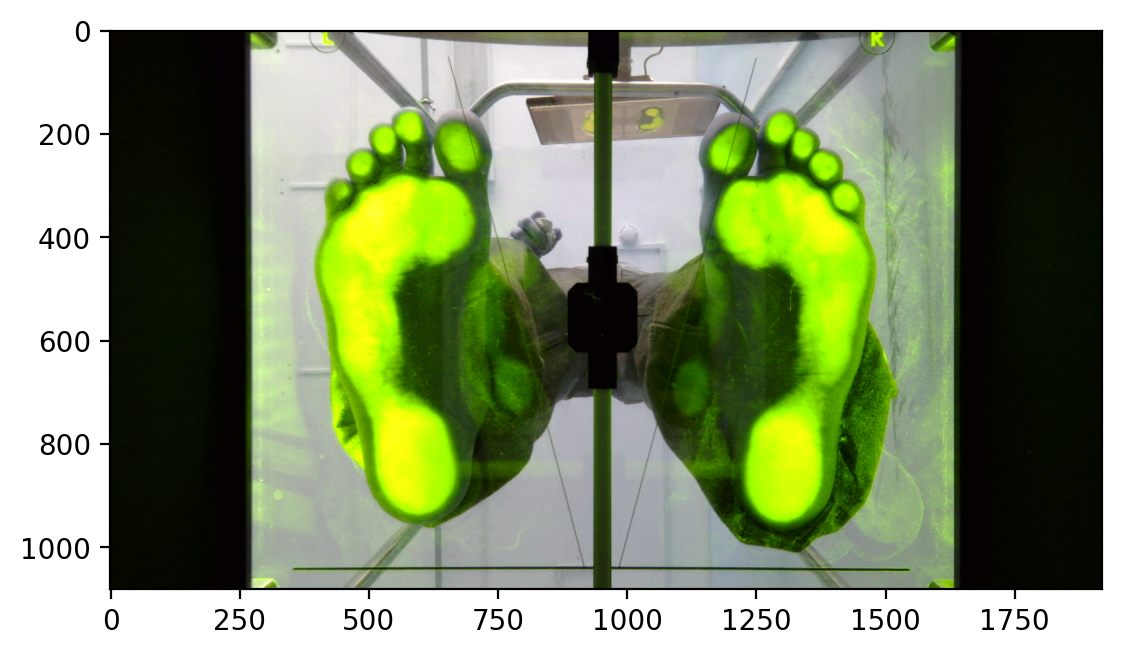

In [95]:
image = cv.imread("./плантограммы/Img (copy 4).png")

plt.imshow(image)

In [96]:
def split_foot(image):
    leftPad = 280
    rightPad = 1920 - 1630
    yPad = 50
    assert image.shape == (1080, 1920, 3)
    return image[yPad:,leftPad:880,:], image[yPad:,1025:-rightPad,:]


(1030, 600, 3) (1030, 605, 3)


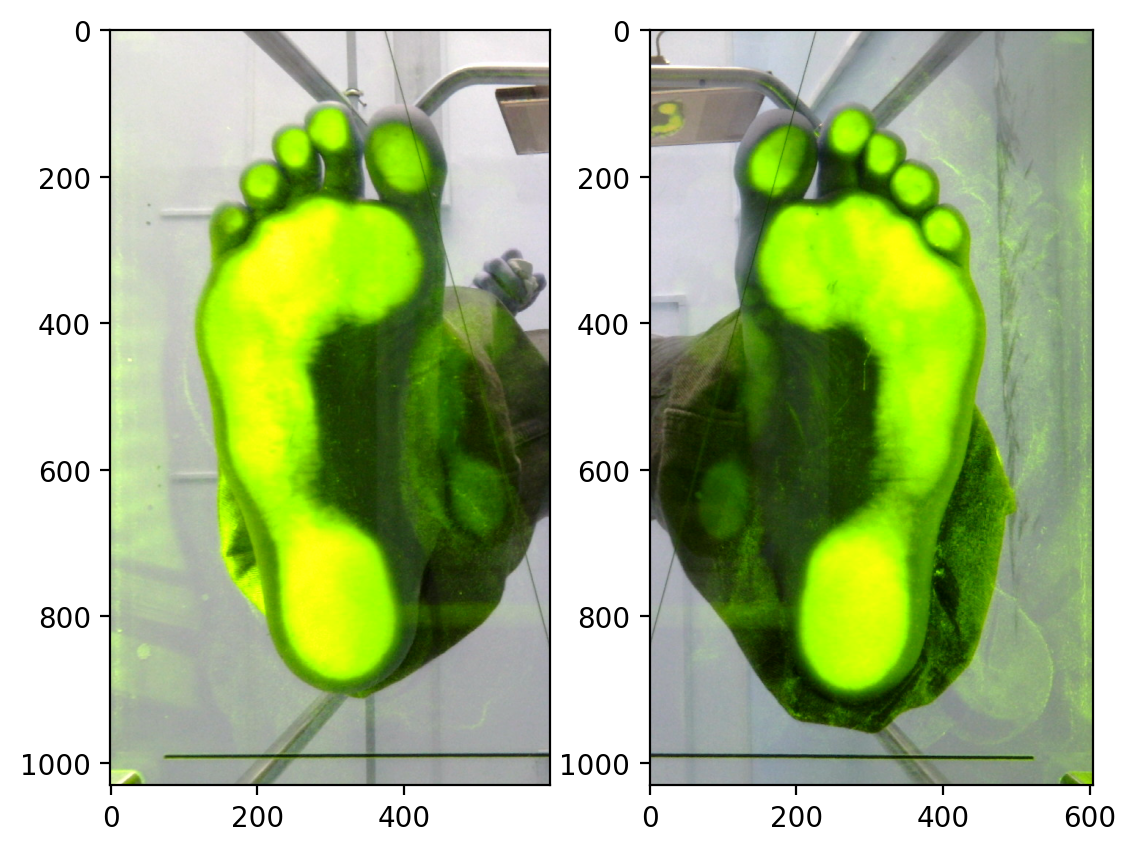

In [97]:
footL, footR = split_foot(image)
fig, (ax1, ax2) = plt.subplots(1, 2)
ax1.imshow(footL)
ax2.imshow(footR)
# ax1.grid(which='major')
# ax1.set_yticks(np.linspace(0, 1100, 65), )
print(footL.shape, footR.shape)

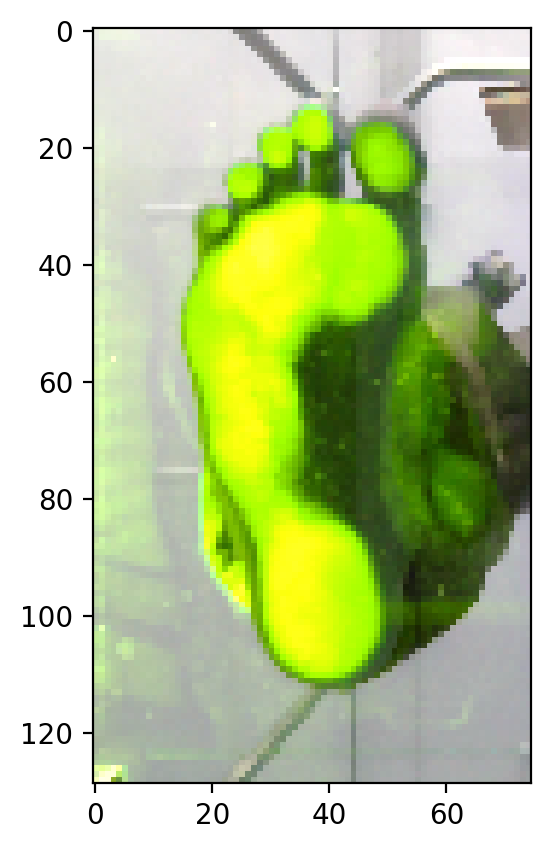

In [133]:
downFootL = ski.measure.block_reduce(footL, block_size=(2, 2, 1), func=np.max)
downFootL = ski.measure.block_reduce(downFootL, block_size=(2, 2, 1), func=np.max)
downFootL = ski.measure.block_reduce(downFootL, block_size=(2, 2, 1), func=np.max)


hsv = cv.cvtColor(downFootL, cv.COLOR_RGB2HSV)

plt.imshow(downFootL)

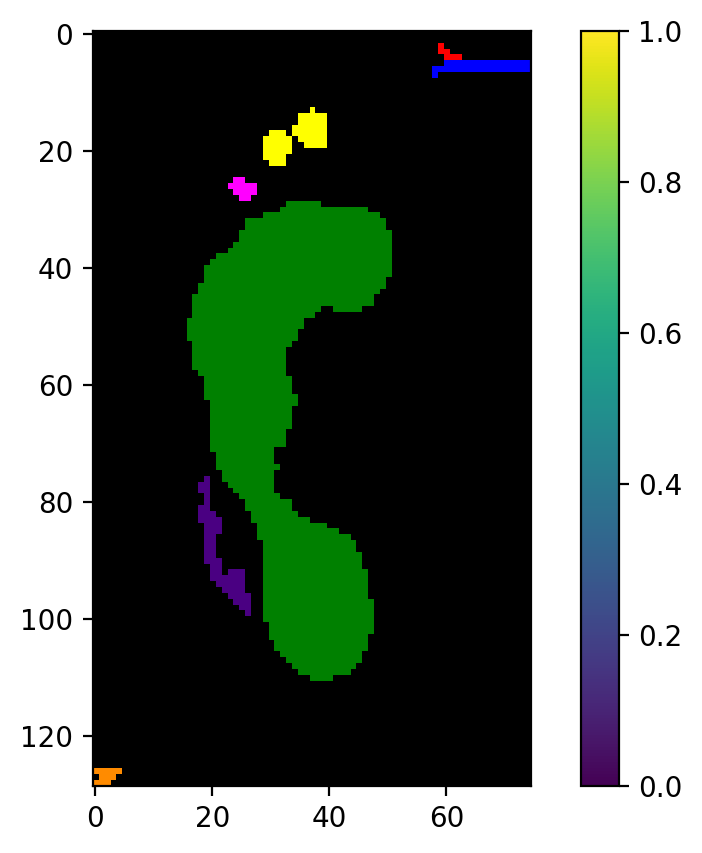

In [187]:
hsv = cv.cvtColor(downFootL, cv.COLOR_RGB2HSV)

highBonudary = hsv[...,2] > 245
lowBoundary = hsv[...,2] < 40

V = hsv[...,2]

# V[highBonudary] = 1
# V[lowBoundary] = 1
V[~(lowBoundary | highBonudary)] = 0

markers = ski.measure.label(V, connectivity=2)

markers = ski.morphology.remove_small_objects(markers, max_size=3)

plt.imshow(ski.color.label2rgb(markers))
plt.colorbar()



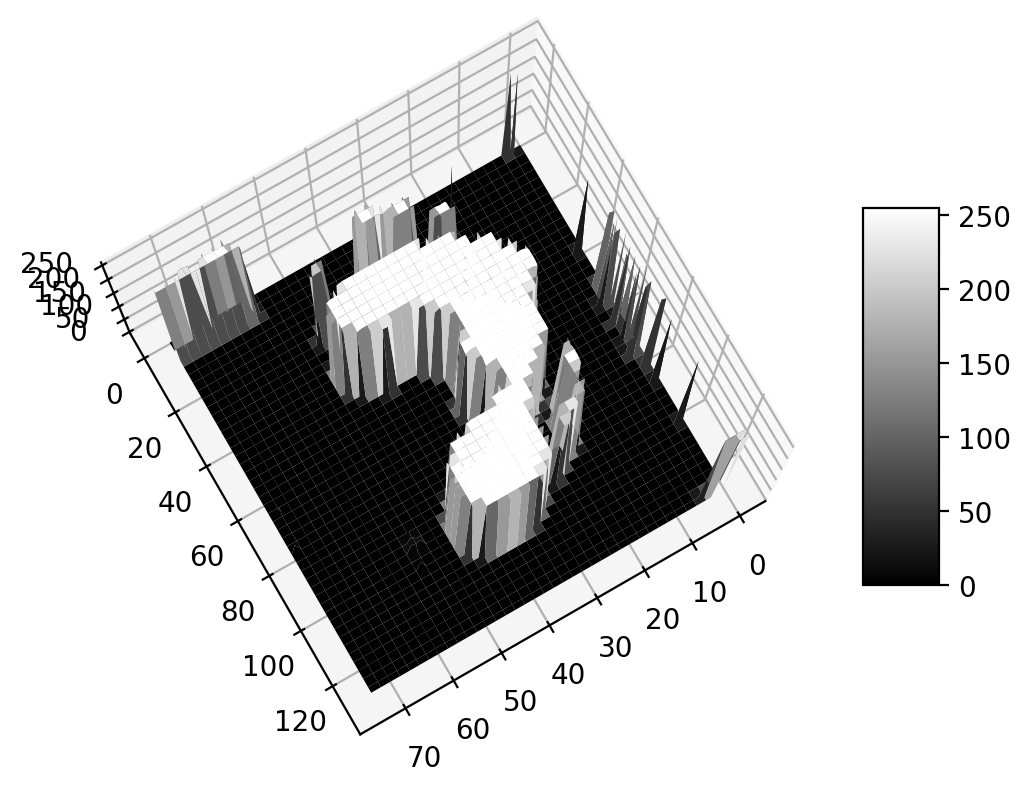

In [192]:
fig = plt.figure()
ax = fig.add_subplot(projection='3d')
ax.view_init(elev=80, azim=60, roll=0)
# Grab some test data.
# X, Y, Z = 
# X = np.meshgrid(np.arange(0, hsv.shape[0], 1))[0]
# Y = np.meshgrid(np.arange(0, hsv.shape[1], 1))[0]

X = np.arange(0, hsv.shape[1], 1)
Y = np.arange(0, hsv.shape[0], 1)

XX, YY = np.meshgrid(X, Y)
# Plot a basic wireframe.
# ax.plot_wireframe(X, Y, Z, rstride=10, cstride=10)

surf = ax.plot_surface(XX, YY, hsv[...,2], cmap=matplotlib.cm.gray, antialiased=True)

fig.colorbar(surf, shrink=0.5, aspect=5)

plt.show()

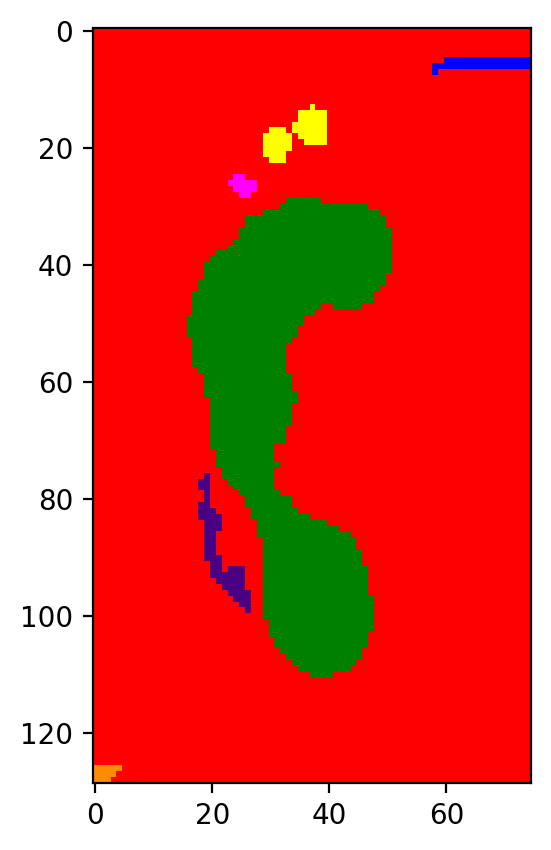

In [191]:
labels = ski.segmentation.watershed(hsv[...,2], markers)

plt.imshow(ski.color.label2rgb(labels))